# Level 3A — Apple Silicon MPS profiling

This notebook benchmarks a pinned tiny GPT-2 model on MPS when available. If MPS is unavailable, `auto` uses CPU and labels every result as CPU. It never selects CUDA. Ordinary timing, optional resource sampling, PyTorch operator profiling, and opt-in MPS OS Signposts are separate passes. No hardware counters are collected.

## Configuration and phase definitions

The default is deliberately small. Change `DEVICE_REQUESTED` to `mps` to require MPS; unavailable MPS then raises instead of silently falling back. The pinned commit is used for both model and tokenizer. Prefill is a full-prompt forward that produces first-token logits. Decode is each subsequent one-token forward with KV cache reuse. Timing includes the Python forward call and device synchronization, and excludes tokenization, argmax, and mask updates. The fixed-length loop ignores EOS.

Resource sampling is optional and adds observer overhead. Phase snapshots are outside the model-forward timers; periodic samples can overlap model execution. When monitoring is enabled, a 32-token generation workload supplies a longer sampling window. Every new run writes to a unique `RUN_DIR`.

In [1]:
import json
import random
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display
from transformers import AutoModelForCausalLM, AutoTokenizer

from profiling_mvp.instruments_capture import capture_instruments
from profiling_mvp.resource_monitor import (ResourceMonitor, SAMPLE_COLUMNS,
    read_memory, save_charts, summarize_resources)
from profiling_mvp.level2 import (Workload, benchmark_workloads, profile_phase,
                                  summarize_workloads)
from profiling_mvp.level3_mps import (DEFAULT_MODEL_ID, DEFAULT_REVISION, build_report,
    capabilities, capture_signposts, level2_comparison_status, make_metadata,
    require_commit, select_device)

MODEL_ID = DEFAULT_MODEL_ID
REVISION = require_commit(DEFAULT_REVISION)
DEVICE_REQUESTED = "mps"
SEED = 42
WARMUP = 1
REPEATS = 2
ENABLE_RESOURCE_MONITORING = True
RESOURCE_INTERVAL_S = 0.01
WORKLOADS = [Workload("prompt_length", 32, 4, 1),
             Workload("prompt_length", 64, 4, 1),
             Workload("one_token", 32, 1, 1)]
if ENABLE_RESOURCE_MONITORING:
    WORKLOADS.append(Workload("resource_timeline", 64, 32, 1))
PROFILE_WORKLOADS = [WORKLOADS[0]]
ENABLE_MPS_SIGNPOSTS = True
ENABLE_INSTRUMENTS_CAPTURE = False
INSTRUMENTS_TIME_LIMIT_S = 60
INSTRUMENTS_TIMEOUT_S = 110
OUTPUT_DIR = Path("results/notebook_level3_mps")
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists() and (PROJECT_ROOT.parent / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not OUTPUT_DIR.is_absolute():
    OUTPUT_DIR = PROJECT_ROOT / OUTPUT_DIR
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR = OUTPUT_DIR / "runs" / RUN_ID
TRACE_DIR = RUN_DIR / "traces"
RUN_DIR.mkdir(parents=True, exist_ok=False)
random.seed(SEED)
torch.manual_seed(SEED)
DEVICE, FALLBACK_REASON = select_device(DEVICE_REQUESTED)
print(f"Selected device: {DEVICE}; fallback: {FALLBACK_REASON}; capabilities: {capabilities()}")

Selected device: mps; fallback: None; capabilities: {'mps_built': True, 'mps_runtime_available': True, 'mps_synchronize_available': True, 'mps_signpost_start_available': True, 'mps_signpost_stop_available': True, 'mps_signpost_context_available': True, 'torch_profiler_mps_activity_available': False, 'instruments_app_available': True, 'xctrace_available': True}


## Load once, then benchmark

Model download and tokenization happen outside inference timing. Both `from_pretrained` calls use the same exact commit SHA. The library may leave its resolved-hash attribute empty for a local snapshot; metadata retains the requested SHA and records that distinction.

In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=REVISION).to(DEVICE).eval()
resource_monitor = ResourceMonitor(DEVICE, RUN_ID, RESOURCE_INTERVAL_S) if ENABLE_RESOURCE_MONITORING else None
raw = benchmark_workloads(model, tokenizer, WORKLOADS, DEVICE, WARMUP, REPEATS, RUN_ID,
    observer_factory=resource_monitor.observer_factory if resource_monitor else None)
# The revision is pinned by the two loading calls, even if transformers leaves _commit_hash unset.
raw["model_revision"] = REVISION
summary, stability = summarize_workloads(raw)
resource_samples = (resource_monitor.samples_dataframe() if resource_monitor else
                    pd.DataFrame(columns=SAMPLE_COLUMNS))
resource_summary = summarize_resources(resource_samples, raw, WORKLOADS,
    RESOURCE_INTERVAL_S if ENABLE_RESOURCE_MONITORING else None,
    ENABLE_RESOURCE_MONITORING)
assert len(raw) == len(WORKLOADS) * REPEATS
assert set(raw.status).issubset({"ok", "failed", "skipped", "unsupported"})
raw.to_csv(RUN_DIR / "raw_runs.csv", index=False)
summary.to_csv(RUN_DIR / "summary.csv", index=False)
stability.to_csv(RUN_DIR / "stability_summary.csv", index=False)
resource_samples.to_csv(RUN_DIR / "resource_samples.csv", index=False)
resource_summary.to_csv(RUN_DIR / "resource_summary.csv", index=False)
display(resource_summary[["workload", "phase", "status", "periodic_sample_count",
    "process_rss_mib_baseline_median", "mps_allocated_mib_baseline_median",
    "mps_driver_allocated_mib_baseline_median"]])
display(summary[["workload", "status", "runs_ok", "runs_requested",
                 "prefill_latency_s_median", "decode_latency_s_median",
                 "end_to_end_tokens_per_s_median"]])

Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,workload,phase,status,periodic_sample_count,process_rss_mib_baseline_median,mps_allocated_mib_baseline_median,mps_driver_allocated_mib_baseline_median
0,prompt_length_p32_n4_b1,prefill,observed,0,556.695312,0.398193,42.703125
1,prompt_length_p32_n4_b1,decode,observed,2,556.703125,0.399414,42.703125
2,prompt_length_p64_n4_b1,prefill,observed,0,562.757812,0.398682,44.765625
3,prompt_length_p64_n4_b1,decode,observed,2,562.781250,0.400879,44.765625
4,one_token_p32_n1_b1,prefill,observed,0,562.804688,0.398193,44.765625
5,one_token_p32_n1_b1,decode,not_applicable_no_decode_steps,0,NaN,NaN,NaN
6,resource_timeline_p64_n32_b1,prefill,observed,0,585.000000,0.398682,45.203125
7,resource_timeline_p64_n32_b1,decode,observed,14,585.039062,0.400879,45.203125


,workload,status,runs_ok,runs_requested,prefill_latency_s_median,decode_latency_s_median,end_to_end_tokens_per_s_median
0,prompt_length_p32_n4_b1,ok,2,2,0.004512,0.008461,312.377903
1,prompt_length_p64_n4_b1,ok,2,2,0.004193,0.007176,352.664497
2,one_token_p32_n1_b1,ok,2,2,0.003410,NaN,293.708299
3,resource_timeline_p64_n32_b1,ok,2,2,0.004283,0.069972,430.969313


## Operator profiling

Each PyTorch trace captures one forward. Decode prepares Prefill and the KV cache **before** the trace. On MPS, this installed PyTorch profiler offers CPU activity only, so device timing columns stay null. Operator aggregation in the report sums self CPU time across disjoint input-shape groups for the single capture; inclusive totals overlap.

In [3]:
operator_rows, profile_runs = [], []
for workload in PROFILE_WORKLOADS:
    for phase in ("prefill", "decode"):
        rows, info = profile_phase(model, tokenizer, workload, phase, DEVICE, TRACE_DIR)
        operator_rows.extend(rows)
        profile_runs.append(info)
operators = pd.DataFrame(operator_rows, columns=["workload", "phase", "device", "operator",
    "input_shapes", "cpu_calls", "self_cpu_time_us", "total_cpu_time_us",
    "self_device_time_us", "total_device_time_us", "device_calls",
    "cpu_memory_bytes", "self_cpu_memory_bytes", "device_memory_bytes",
    "self_device_memory_bytes", "trace"])
operators.to_csv(RUN_DIR / "operator_summary.csv", index=False)
(RUN_DIR / "profile_runs.json").write_text(json.dumps(profile_runs, indent=2))
display(pd.DataFrame(profile_runs))

USDT:2026-10-16 07:19:15 18445:7839390 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-16 07:19:15 18445:7839390 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-10-16 07:19:15 18445:7839390 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-16 07:19:15 18445:7839390 SyncActivityProfilerHandler.cpp:46] profiler_stop


,workload,phase,device,status,error,trace,activities_used
0,prompt_length_p32_n4_b1,prefill,mps,ok,None,/Users/Huy/VSCode/DataProccessing/profiling_fr...,[CPU]
1,prompt_length_p32_n4_b1,decode,mps,ok,None,/Users/Huy/VSCode/DataProccessing/profiling_fr...,[CPU]


## Direct Signpost emission

`ENABLE_MPS_SIGNPOSTS=True` emits PyTorch MPS signposts around one Prefill and one cached Decode forward in this notebook process. This call neither starts Instruments nor saves a trace. It is independent of the automatic `xctrace` pass below. For manual capture, start the `os_signpost` instrument in Instruments before running this cell, then save and validate the capture yourself.

In [4]:
signpost_runs = []
for workload in PROFILE_WORKLOADS:
    for phase in ("prefill", "decode"):
        signpost_runs.append(capture_signposts(model, tokenizer, workload, phase,
            DEVICE, enabled=ENABLE_MPS_SIGNPOSTS))
(RUN_DIR / "signpost_runs.json").write_text(json.dumps(signpost_runs, indent=2))
display(pd.DataFrame(signpost_runs))

,workload,phase,device,status,error,capture_kind,trace,mode,wait_until_completed
0,prompt_length_p32_n4_b1,prefill,mps,emitted,None,os_signposts,None,interval,False
1,prompt_length_p32_n4_b1,decode,mps,emitted,None,os_signposts,None,interval,False


## Optional bounded Instruments capture

Set `ENABLE_INSTRUMENTS_CAPTURE=True` in the configuration cell to launch a **separate** Python worker under `xcrun xctrace`. The worker loads the same pinned model, warms up, then emits one phase's MPS signposts. `xctrace` records with the locally discovered `Logging` template plus `os_signpost` instrument, a 60-second recording limit, and a 110-second subprocess timeout. Each phase gets a unique `.trace` directory under `OUTPUT_DIR/instruments/<RUN_ID>/`. The capture pass does not enter ordinary benchmark timings. `instruments_runs` records separate states for emission, recording, saved trace, structural export, and expected PyTorchMPS intervals. Leave it disabled to benchmark without Instruments. Run the notebook from the project root or use absolute `OUTPUT_DIR` to keep results in one place.

In [5]:
instruments_runs = []
if ENABLE_INSTRUMENTS_CAPTURE:
    for workload in PROFILE_WORKLOADS:
        for phase in ("prefill", "decode"):
            instruments_runs.append(capture_instruments(
                model_id=MODEL_ID, revision=REVISION, workload=workload, phase=phase,
                output_dir=RUN_DIR.resolve(), run_id=RUN_ID,
                time_limit_s=INSTRUMENTS_TIME_LIMIT_S,
                timeout_s=INSTRUMENTS_TIMEOUT_S))
    manifest = RUN_DIR / "instruments" / RUN_ID / "capture_runs.json"
    manifest.write_text(json.dumps(instruments_runs, indent=2))
    display(pd.DataFrame(instruments_runs)[["workload", "phase", "status",
        "signposts_emitted", "recording_started", "trace_saved",
        "trace_structurally_readable", "expected_signpost_events_present",
        "trace_validated", "trace", "error"]])
else:
    print("Instruments capture disabled; no .trace artifact claimed.")

Instruments capture disabled; no .trace artifact claimed.


## Results, resource charts, and report

The four new plots use successful benchmark rows and available memory observations only. Undefined one-token Decode values are labelled N/A. Memory snapshots and sampled maxima are distinct; periodic sampling can miss short spikes. All CSV, PNG, JSON, and trace outputs for this notebook execution are under `RUN_DIR`. Instruments remains a separate, optional pass.

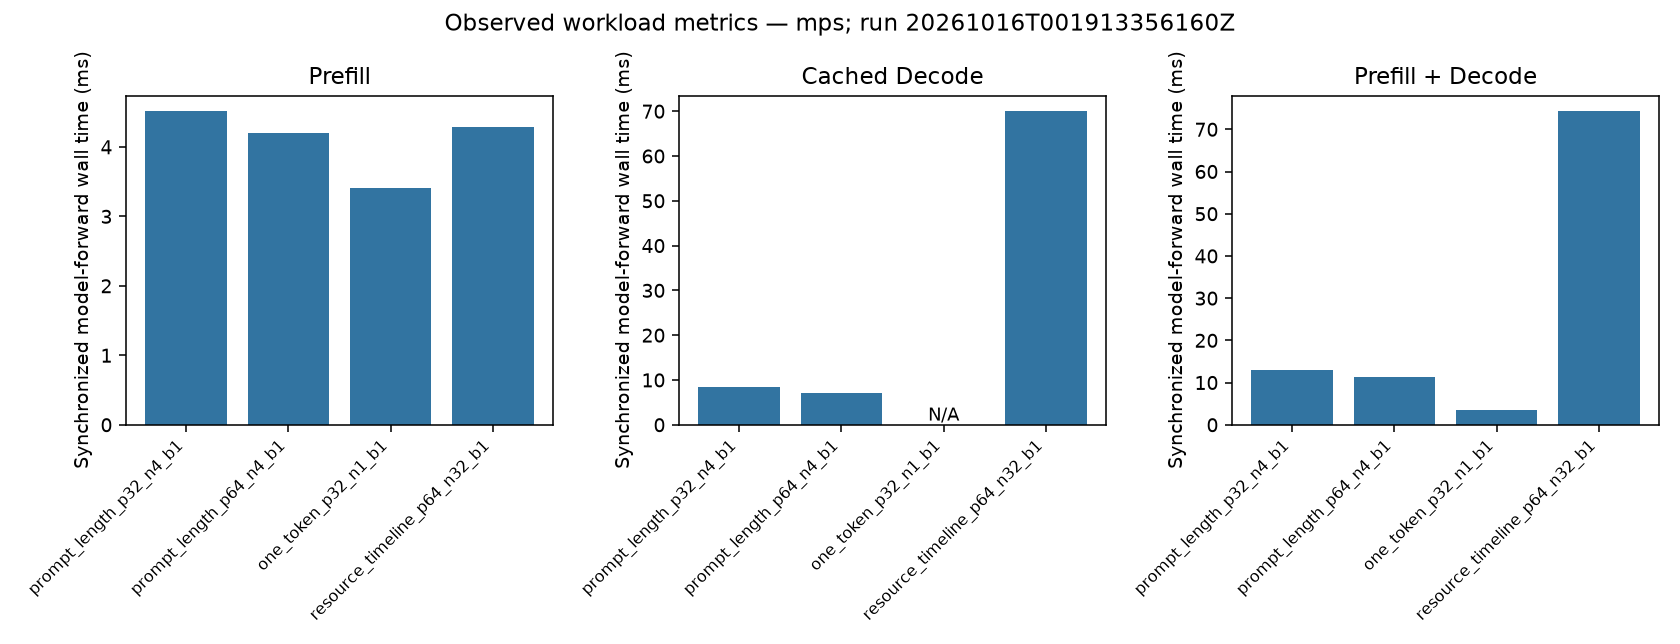

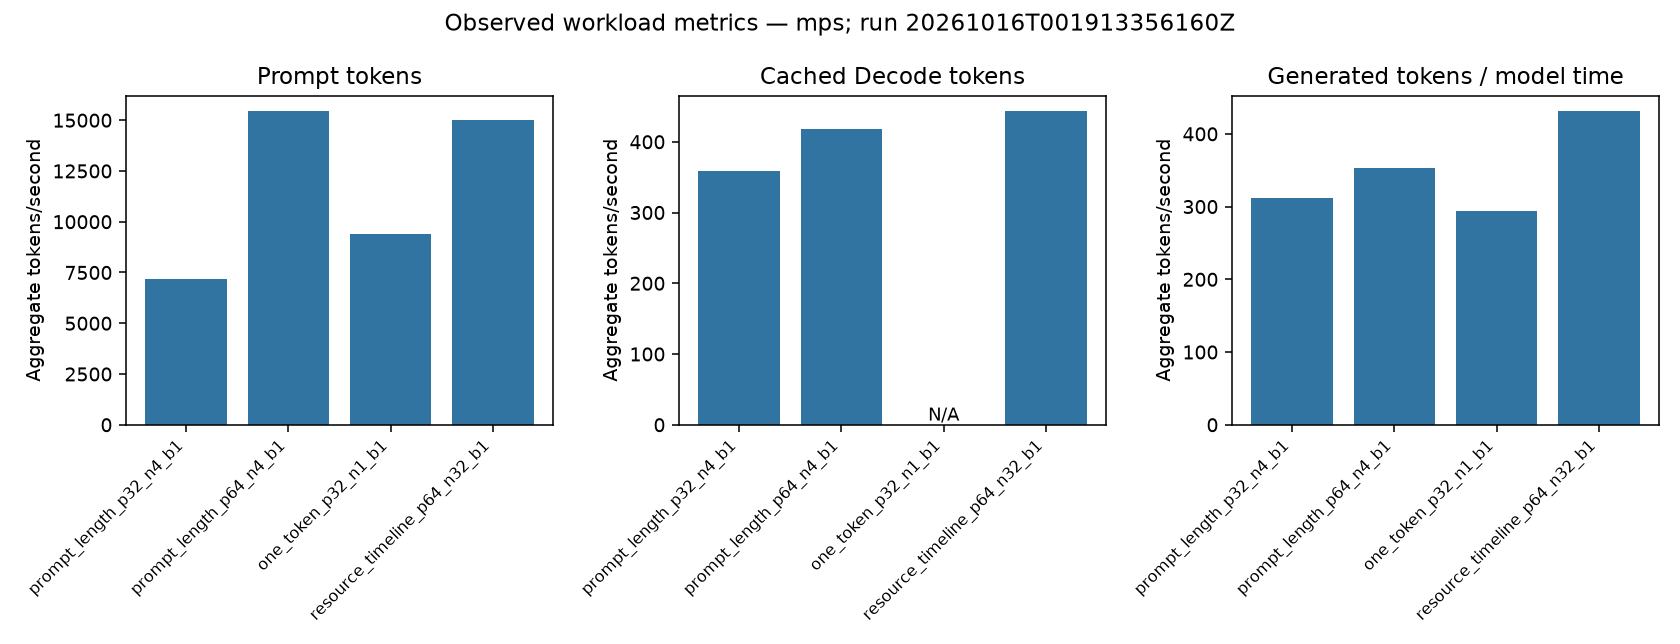

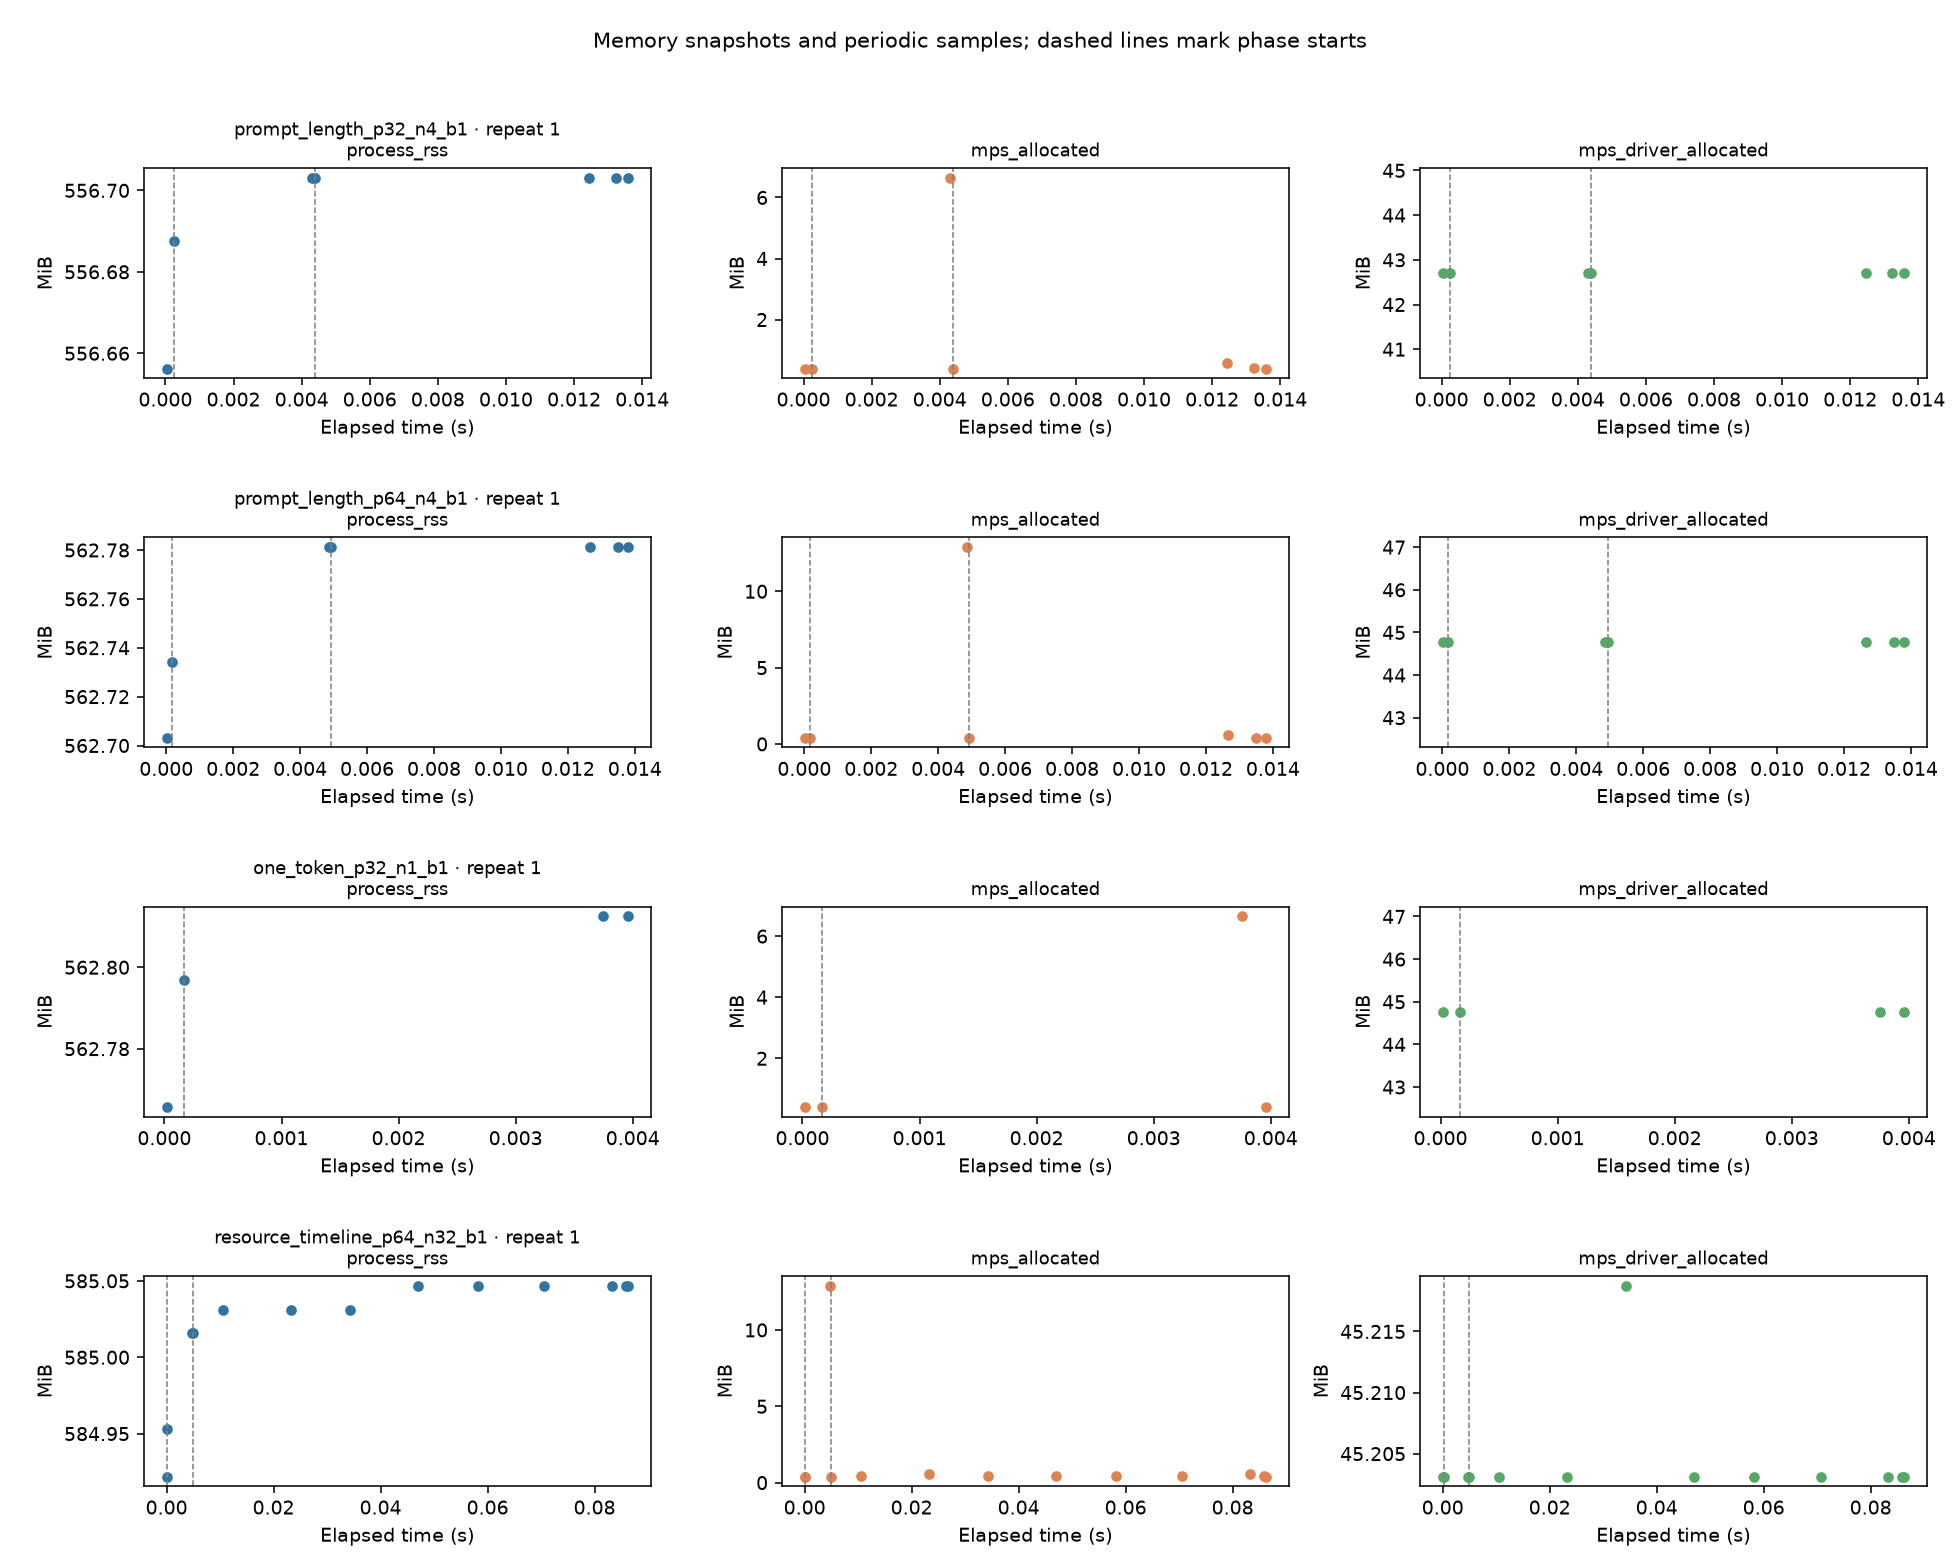

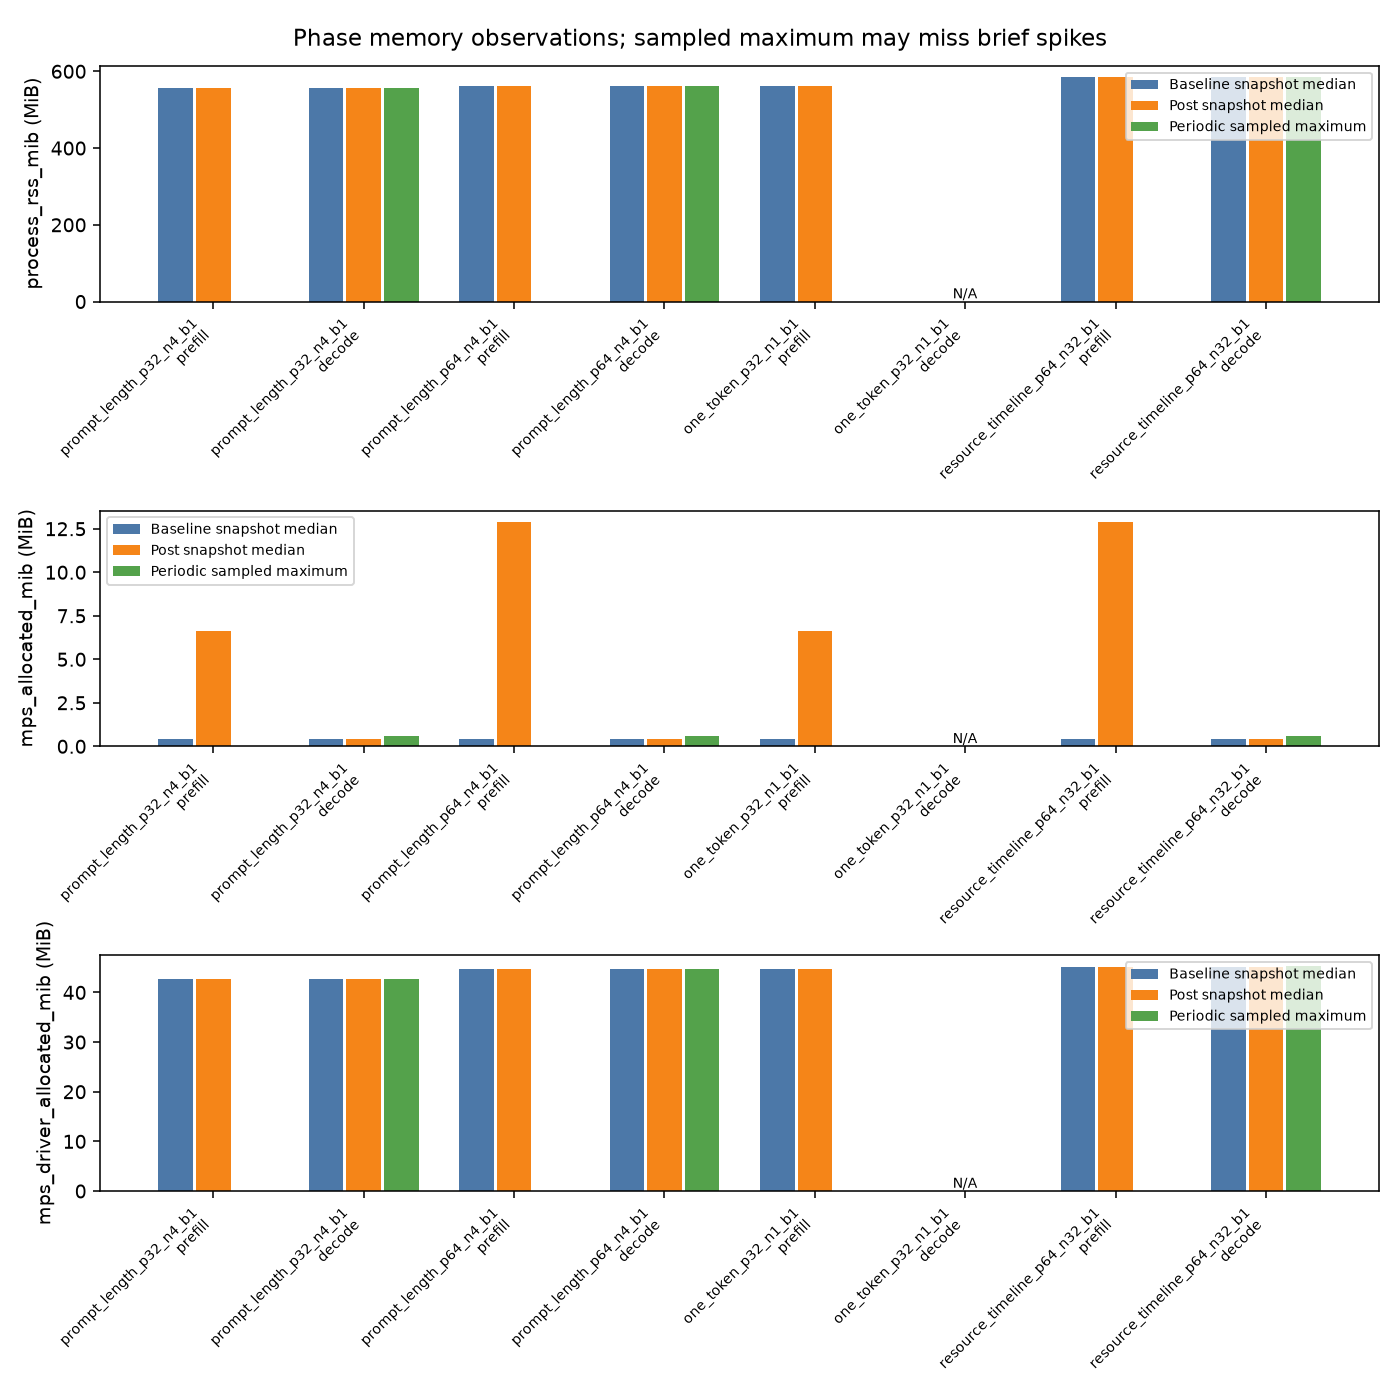

# Level 3A MPS profiling report

Run: `20261016T001913356160Z`; selected device: `mps`; requested: `mps`.
Model/tokenizer: `sshleifer/tiny-gpt2` at pinned commit `5f91d94bd9cd7190a9f3216ff93cd1dd95f2c7be`; dtype: `torch.float32`.
macOS 26.6.2; Python 3.12.11; PyTorch 2.14.1.

Capabilities: MPS build=True; runtime=True; MPS synchronization=True; OS Signpost context=True; torch.profiler MPS activity=False.

## Measurement semantics

1 warm-up and 2 measured repeats per workload. Model loading and tokenization are outside timing.
Prefill times one full-prompt forward and includes the forward that produces the first token's logits. Decode times the remaining cached one-token forwards. Argmax, mask updates, and profiler overhead are outside ordinary timings.
Synchronized wall time includes the Python model call and device synchronization. It is not isolated GPU execution time. Batch rates count tokens over all sequences; per-sequence rates use one sequence over the same batch time.
Fixed-le

In [6]:
charts = save_charts(summary, resource_summary, resource_samples, RUN_DIR, DEVICE, RUN_ID)
resource_capabilities = read_memory(DEVICE)
sampler_errors = [error for sampler in resource_monitor.samplers for error in sampler.errors] if resource_monitor else []
meta = make_metadata(model_id=MODEL_ID, revision=REVISION, tokenizer=tokenizer,
    model=model, requested_device=DEVICE_REQUESTED, device=DEVICE,
    fallback_reason=FALLBACK_REASON, seed=SEED, workloads=WORKLOADS,
    profile_workloads=PROFILE_WORKLOADS, warmup=WARMUP, repeats=REPEATS,
    signposts_enabled=ENABLE_MPS_SIGNPOSTS, run_id=RUN_ID,
    profile_runs=profile_runs, signpost_runs=signpost_runs,
    instruments_runs=instruments_runs, instruments_settings={"enabled": ENABLE_INSTRUMENTS_CAPTURE,
        "time_limit_s": INSTRUMENTS_TIME_LIMIT_S, "timeout_s": INSTRUMENTS_TIMEOUT_S})
level2_path = PROJECT_ROOT / "results/notebook_level2/metadata.json"
level2_meta = json.loads(level2_path.read_text()) if level2_path.exists() else None
comparison_status = level2_comparison_status(level2_meta, meta)
meta["level2_comparison_status"] = comparison_status
meta["resource_monitoring"] = {"enabled": ENABLE_RESOURCE_MONITORING,
    "sampling_interval_s": RESOURCE_INTERVAL_S if ENABLE_RESOURCE_MONITORING else None,
    "sample_count": len(resource_samples), "sampler_errors": sampler_errors,
    "run_statuses": resource_monitor.run_statuses() if resource_monitor else [],
    "metric_availability_probe": resource_capabilities,
    "phase_boundary_snapshots_outside_timers": True,
    "periodic_sampling_may_contend_with_benchmark": ENABLE_RESOURCE_MONITORING,
    "periodic_polls_synchronize_mps": False}
meta["resource_metric_semantics"] = {
    "unit": "MiB (bytes / 2**20)",
    "process_rss_mib": "Current Python process resident set size; not GPU-only memory.",
    "mps_allocated_mib": "PyTorch MPS tensor allocations; excludes cached MPSAllocator blocks.",
    "mps_driver_allocated_mib": "Metal driver allocation for this process; includes MPSAllocator cache and MPS/MPSGraph allocations, not total physical GPU use.",
    "sampled_peak": "Maximum periodic observation; not an instantaneous hardware peak."}
meta["resource_artifacts"] = {"resource_samples_csv": str(RUN_DIR / "resource_samples.csv"),
    "resource_summary_csv": str(RUN_DIR / "resource_summary.csv"), "charts": charts}
meta["output_dir"] = str(RUN_DIR)
meta["artifacts"] = {
    "raw_runs_csv": str(RUN_DIR / "raw_runs.csv"),
    "summary_csv": str(RUN_DIR / "summary.csv"),
    "stability_summary_csv": str(RUN_DIR / "stability_summary.csv"),
    "resource_samples_csv": str(RUN_DIR / "resource_samples.csv"),
    "resource_summary_csv": str(RUN_DIR / "resource_summary.csv"),
    "operator_summary_csv": str(RUN_DIR / "operator_summary.csv"),
    "profile_runs_json": str(RUN_DIR / "profile_runs.json"),
    "signpost_runs_json": str(RUN_DIR / "signpost_runs.json"),
    "instruments_manifest_json": str(manifest) if ENABLE_INSTRUMENTS_CAPTURE else None,
    "report_md": str(RUN_DIR / "report.md"),
    "charts": charts}
(RUN_DIR / "metadata.json").write_text(json.dumps(meta, indent=2, default=str))
report = build_report(meta, summary, operators, profile_runs, signpost_runs,
                      comparison_status, instruments_runs, resource_summary)
(RUN_DIR / "report.md").write_text(report)
for name, item in charts.items():
    if item["status"] == "saved":
        display(Image(filename=item["path"]))
    else:
        print(f"{name}: unavailable — {item['reason']}")
print(report)

## Limits

Synchronized wall time is not isolated GPU time. PyTorch `CPU` activity traces are host operator traces even when the model runs on MPS. A validated Instruments signpost trace proves that PyTorchMPS intervals were recorded for the launched worker; it does not by itself provide hardware counters, GPU utilization, cache misses, DRAM bandwidth, or isolated GPU execution time. Signpost and Instruments overhead stays outside ordinary benchmark rows.

CPU RSS is process memory, MPS tensor allocation excludes cached blocks, and driver allocation is a process driver counter rather than total physical GPU memory. Sampled maxima can miss brief spikes; short workloads may have no periodic samples.